# Kahramanmaraş 2023 · MMI Intensity Mapper demo

Bu not defteri `mmi_mapper` paketinin uçtan uca kullanımını gösterir:

1. Eski formül ile yayımlanmış IPE'lerin karşılaştırılması
2. Sonlu fay (GEM izi + Thingbaijam 2017) ve GMPE + GMICE zinciri
3. Mantık ağacı, %16/%50/%84 ve aşma olasılıkları
4. KOERI istasyonlarıyla doğrulama
5. Nüfus maruziyeti (PAGER mantığı) ve katmanlı harita

> Bu araç **olmuş** bir depremin etkisini tahmin eder; deprem öngörüsü yapmaz.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
pd.set_option("display.float_format", "{:,.2f}".format)
from mmi_mapper import ipe, observations as O
from mmi_mapper.model import Event, run_scenario, MODEL_LABELS
from mmi_mapper.uncertainty import add_uncertainty
from mmi_mapper.benchmark import predict_for_observations, metrics
from mmi_mapper.exposure import exposure
from mmi_mapper.grid import run_latlon_grid
from mmi_mapper.mapping import layered_map

## 1. Eski formül neden kaldırıldı?

In [2]:
r = np.array([25, 50, 100, 200, 300.0])
pd.DataFrame({"Repi (km)": r,
              "Eski formül": ipe.legacy_unverified(7.8, r, 10)[0],
              "Allen 2012 Rhyp": ipe.allen2012_rhyp(7.8, np.hypot(r, 10))[0],
              "Bayrak 2019 R3": ipe.bayrak2019(7.8, r, 10, "R3")[0]}).assign(
    **{"Fark (eski − Allen)": lambda d: d["Eski formül"] - d["Allen 2012 Rhyp"]})

,Repi (km),Eski formül,Allen 2012 Rhyp,Bayrak 2019 R3,Fark (eski − Allen)
0,25.00,9.22,7.95,8.72,1.27
1,50.00,8.80,7.46,7.73,1.34
2,100.00,8.30,6.74,6.71,1.56
3,200.00,7.66,5.88,5.70,1.77
4,300.00,7.17,5.36,5.10,1.82


## 2. Senaryo: Pazarcık Mw 7.8, büyük şehirler

In [3]:
ev = Event(7.8, 37.2256, 37.0143, 10.0, event_id="us6000jllz")
cities = {"Kahramanmaraş": (37.5753, 36.9228), "Antakya": (36.2023, 36.1613), "Gaziantep": (37.0662, 37.3833),
          "Malatya": (38.3552, 38.3095), "Adana": (36.9914, 35.3308)}
lat, lon = zip(*cities.values())
df, rup = run_scenario(ev, lat, lon, vs30=400)
df = add_uncertainty(df, finite=rup.is_finite)
df.index = list(cities)
print(rup.source, f"L = {rup.length:.0f} km, W = {rup.width:.0f} km")
df[["repi", "rjb", "rrup", "legacy", "allen2012_rhyp", "allen2012_rrup", "bayrak2019", "kale2015_wgrw12",
    "lt_p16", "lt_p50", "lt_p84", "p_ge_7", "p_ge_8"]]

GEM GAF-DB izi (ME_TRCS056) + Thingbaijam 2017 L = 234 km, W = 18 km


,repi,rjb,rrup,legacy,allen2012_rhyp,allen2012_rrup,bayrak2019,kale2015_wgrw12,lt_p16,lt_p50,lt_p84,p_ge_7,p_ge_8
Kahramanmaraş,39.65,12.47,12.47,8.95,7.66,7.81,8.06,7.62,6.90,8.00,9.26,0.82,0.50
Antakya,136.76,19.30,20.23,8.03,6.36,7.52,6.25,7.29,6.48,7.60,8.82,0.70,0.36
Gaziantep,37.25,50.82,53.18,8.99,7.71,6.63,8.15,6.40,5.75,6.77,7.94,0.42,0.15
Malatya,169.51,65.77,65.77,7.83,6.09,6.41,5.94,6.15,5.43,6.43,7.49,0.29,0.08
Adana,151.88,102.78,102.78,7.93,6.23,5.93,6.10,5.68,4.99,5.96,6.98,0.16,0.04


Antakya'da Repi ≈ 137 km iken Rrup ≈ 20 km'dir: nokta kaynak varsayımı büyük depremlerde şiddeti ciddi biçimde düşük tahmin eder.

## 3. Doğrulama: KOERI istasyonları

In [4]:
obs = O.load_koeri(event_id="us6000jllz")
res, _ = predict_for_observations(ev, obs)
display(res[["station", "rrup", "pgv_cms", "obs_mmi", "legacy", "allen2012_rrup", "kale2015_wgrw12", "lt_p50"]])
metrics(res)

,station,rrup,pgv_cms,obs_mmi,legacy,allen2012_rrup,kale2015_wgrw12,lt_p50
0,CMRD,160.11,2.90,4.46,7.74,5.45,5.13,5.41
1,KHMN,12.92,98.34,9.19,9.28,7.79,7.94,8.21
2,KRTS,80.08,14.12,6.52,7.86,6.20,6.16,6.34
3,TUNC,199.83,7.70,5.69,7.27,5.20,4.61,4.98


,grup,model,N,sapma,RMSE,MAE,std
0,tümü,Eski formül (doğrulanmamış),4,-1.57,1.94,1.57,1.31
1,tümü,Allen 2012 · Rhyp,4,0.07,0.99,0.83,1.14
2,tümü,Allen 2012 · Rrup,4,0.30,0.90,0.80,0.98
3,tümü,Bayrak 2019 · R3,4,-0.01,0.78,0.67,0.90
4,tümü,Kale 2015 → WGRW12,4,0.50,0.91,0.84,0.87
5,tümü,Kale 2015 → Bilal & Askan 2014,4,-0.43,0.82,0.75,0.81
6,tümü,Mantık ağacı (ortalama),4,0.18,0.74,0.67,0.83


In [5]:
pd.read_csv("../results/metrics_m6.csv")  # Türkiye Mw ≥ 6 (scripts/run_benchmark.py)

,grup,model,N,sapma,RMSE,MAE,std
0,tümü,Eski formül (doğrulanmamış),54,-2.36,2.45,2.36,0.68
1,tümü,Allen 2012 · Rhyp,54,-0.61,0.89,0.77,0.65
2,tümü,Allen 2012 · Rrup,54,-0.57,0.89,0.78,0.69
3,tümü,Bayrak 2019 · R3,54,-1.63,1.91,1.73,1.02
4,tümü,Kale 2015 → WGRW12,54,-0.17,0.69,0.57,0.67
5,tümü,Kale 2015 → Bilal & Askan 2014,54,0.20,0.96,0.78,0.94
6,tümü,Mantık ağacı (ortalama),54,-0.48,0.80,0.69,0.65


## 4. ML artık modeli (Aşama 4)

In [6]:
pd.read_csv("../results/ml/cv_summary.csv")

,küme,yöntem,N,deprem,sapma,RMSE
0,tümü,omurga (Kale 2015 → WGRW12),949,332,-0.42,0.68
1,tümü,omurga + sabit kaydırma,949,332,0.00,0.54
2,tümü,omurga + LightGBM,949,332,0.00,0.45
3,Mw ≥ 6,omurga (Kale 2015 → WGRW12),54,18,-0.17,0.69
4,Mw ≥ 6,omurga + sabit kaydırma,54,18,0.24,0.71
5,Mw ≥ 6,omurga + LightGBM,54,18,-0.01,0.65
6,Rrup ≤ 50 km,omurga (Kale 2015 → WGRW12),138,87,-0.04,0.59
7,Rrup ≤ 50 km,omurga + sabit kaydırma,138,87,0.38,0.70
8,Rrup ≤ 50 km,omurga + LightGBM,138,87,-0.03,0.53
9,tümü · istasyon bazlı CV,omurga (Kale 2015 → WGRW12),949,332,-0.42,0.68


## 5. Nüfus maruziyeti ve katmanlı harita

In [7]:
table, places, _ = exposure(ev, 3.0, rupture=rup)
table.set_index("MMI").astype(int)

,%16,Medyan,%84
MMI,,,
I,0,0,0
II–III,1863369,0,0
IV,12054035,2302982,0
V,9679190,11397279,3660996
VI,1352247,9482003,10039265
VII,534663,1730637,7147940
VIII,0,570603,3755596
IX,0,0,879707
X+,0,0,0



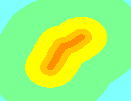
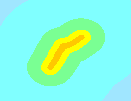
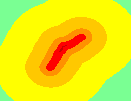
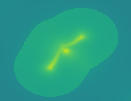
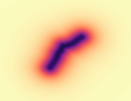
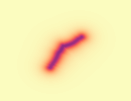

In [8]:
g, _ = run_latlon_grid(ev, 2.5, 0.05, rupture=rup)
layered_map(ev, g, rup, obs, places)